# Deep Neural Network with Keras for MNIST handwritten classification and recognition

Welcome to this end-to-end project that will include various design logics that are required to create stable training and evaluation deep neural network models !

We are going to employ the keras based python deep learning framework that readily offers complex mathematical layers that compute and form weights that are resultant of the data the model is viewing and learning from and then predict on new dataset.

Keras automates large amount of mathetmatical design that helps to rapidly develop and protype datasets and ML logic

![keras basic nn](https://user-images.githubusercontent.com/67789350/102743004-6dad1f00-437c-11eb-9c77-b1c97bceafaf.png)

## Section O : Things to Know 

- Understand how to call in or import [Keras-Based](https://en.wikipedia.org/wiki/Keras) mathematical layers into your colab environment 
- Spend time on how a neural network is built and the logic to implement efficient and [Optimal Training Networks](https://en.wikipedia.org/wiki/Convolutional_neural_network) for image classification 
- Explore the official documentation about the [MNIST Dataset](https://en.wikipedia.org/wiki/MNIST_database)

## Import dependencies

In [36]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.utils import normalize
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Activation
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import SGD
from sklearn.model_selection import KFold
from numpy import mean
from numpy import std

## Section D : Load the data in 

- Let's load in the dataset using Keras 

In [37]:
from keras.datasets import mnist 

(trainsetX, trainsety),(testsetX,testsety) = mnist.load_data()

print('Train: X = {}, y = {}'.format(trainsetX.shape, trainsety.shape)) 
print('Test: X = {}, y = {}'.format(testsetX.shape, testsety.shape))

Train: X = (60000, 28, 28), y = (60000,)
Test: X = (10000, 28, 28), y = (10000,)


## Section I.I : Initial Data Indagation

- Start off by understanding what MNIST Data is in more detail

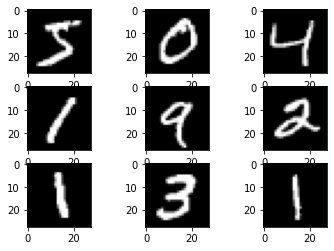

In [38]:
# Display few of the images
for i in range(9):
    plt.subplot(330 + 1 + i)
    plt.imshow(trainsetX[i], cmap=plt.get_cmap('gray'))
plt.show()

The mnist data is a set of images of numbers

- Note down the dimensions and other practical information about the MNIST dataset

In [39]:
print("Diamensions of X train:",trainsetX.shape)
print("Diamensions of y train:",trainsety.shape)
print("Diamensions of X test:",testsetX.shape)
print("Diamensions of y test:",testsety.shape)

Diamensions of X train: (60000, 28, 28)
Diamensions of y train: (60000,)
Diamensions of X test: (10000, 28, 28)
Diamensions of y test: (10000,)


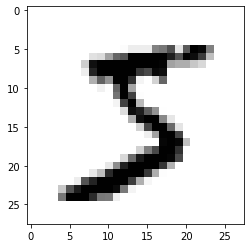

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

In [40]:
plt.imshow(trainsetX[0], cmap=plt.cm.binary) ;   plt.show()
print(trainsetX[0])

The X set contains images of diamension 28x28 pixels with test-train split in the ratio 1:6

## Section I.II : Initial EDA

- Explore the datasets descriptive statistics if needed

In [41]:
# Unique values of output classes
np.unique(trainsety)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [42]:
# Value counts of each classes
print(np.unique(trainsety,return_counts=True)[1])

# Observations : classes fairly balanced

[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [43]:
from scipy.stats import mode as mode
mode(trainsety)

#The most common class is 1 with 6742 images

ModeResult(mode=array([1], dtype=uint8), count=array([6742]))

- Create graphs of the counts of each class

/usr/local/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:ylabel='count'>

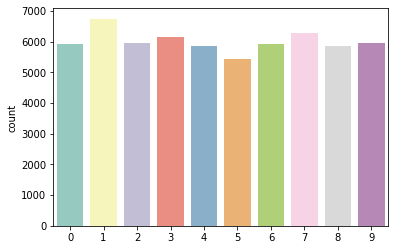

In [44]:
sns.countplot(trainsety,palette="Set3")

- Make deductions upon the class distribution

Classes are distributed approximately evenly.

## Section II : Data Preparation 

- Normalize the pixel value of the all images 

In [45]:
trainsetX = normalize(trainsetX, axis=1)
testsetX = normalize(testsetX, axis=1)

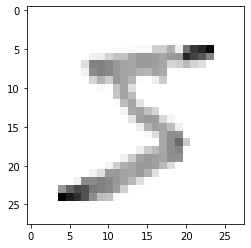

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [46]:
plt.imshow(trainsetX[0], cmap=plt.cm.binary) ;   plt.show()
print(trainsetX[0])

- Why is scaling of the pixel value required ? Make a note


The value of the pixels at the RGB layer in any digital image is in the range of 0-255 as it is captured in analog range.It is rescaled to obtained values in the range 0-1

- Explain the difference between pre-processed images and the normalized images

Preprocessing is done so as to ensure all images are of same diamensions and have same number of pixels or to solve any other inconsistencies within the dataset

Normalization is done so as to make the range of pixel intensity values in the same range, so that the image quality is imporoved and in standardised for better training

## Section III : Model Construction 

- What sort of Neural Network would you employ for this problem statement ?

A Convolutional Neural Network can be used for this dataset

- Write down the skeleton flow of the model 

In [47]:
def define_model():
    #Define the model
    model = Sequential()
    #Add Layers
    model.add(Flatten())
    model.add(Dense(128,activation=tf.nn.relu))
    model.add(Dense(128,activation=tf.nn.relu))
    model.add(Dense(10,activation=tf.nn.softmax))
    #Compile the model
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

- Create a baseline model 

In [48]:
model = define_model()

2021-10-21 03:10:42.655285: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


- Train the model

In [49]:
model.fit (trainsetX,trainsety,epochs=3)

2021-10-21 03:10:43.926257: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


Epoch 1/3
1875/1875 [==============================] - 8s 4ms/step - loss: 0.2664 - accuracy: 0.9225
Epoch 2/3
1875/1875 [==============================] - 7s 4ms/step - loss: 0.1075 - accuracy: 0.9671
Epoch 3/3
1875/1875 [==============================] - 7s 4ms/step - loss: 0.0717 - accuracy: 0.9778


## Section IV : Model Evaluation 

- It is recommeded to to use Kfolds to evaluate your model, what other validation process could you employ ? 

In [50]:
scores, histories = list(), list()
# prepare cross validation
kfold = KFold(5, shuffle=True, random_state=1)
# enumerate splits
for train_ix, test_ix in kfold.split(trainsetX):
    # define model
    model = define_model()
    # select rows for train and test
    trainX, trainY, testX, testY = trainsetX[train_ix], trainsety[train_ix], trainsetX[test_ix], trainsety[test_ix]
    # fit model
    history = model.fit(trainX, trainY, epochs=10, batch_size=32, validation_data=(testX, testY), verbose=0)
    # evaluate model
    val_loss, val_accuracy = model.evaluate(testX, testY, verbose=0)
    print('> %.3f' % (val_accuracy * 100.0))
    # stores scores
    scores.append(val_accuracy)
    histories.append(history)


> 97.517
> 97.042
> 97.100
> 97.467
> 96.967


- What would be the best value for K and why for this baseline model 

K=1

- Evaluate the model accordingly and make a note of it's performance with respect to it's accuracy

Model accuracy at K=1 is 97.517

## Section V : Model Evaluation Metrics 

- Create Graphical plots of the model performance on the train and test set during individual folds

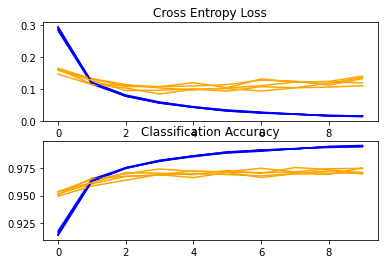

In [51]:
# plot diagnostic learning curves
def summarize_diagnostics(histories):
    for i in range(len(histories)):
        # plot loss
        plt.subplot(2, 1, 1)
        plt.title('Cross Entropy Loss')
        plt.plot(histories[i].history['loss'], color='blue', label='train')
        plt.plot(histories[i].history['val_loss'], color='orange', label='test')
        # plot accuracy
        plt.subplot(2, 1, 2)
        plt.title('Classification Accuracy')
        plt.plot(histories[i].history['accuracy'], color='blue', label='train')
        plt.plot(histories[i].history['val_accuracy'], color='orange', label='test')
    plt.show()
    
summarize_diagnostics(histories)

- Is your model overfitting , underfitting or has the optimum fit ? Provide reasoning 

Cross Enthropy loss of the models keeps decreasing in subsequent iterations and reaches optima at K=5 with 96.967% accuracy

- Get the loss and validation loss of the model and also the accuracy and the validation accuracy 

In [69]:
loss, accuracy = model.evaluate(testX, testY, verbose=0)

print("Validation Loss : {}%".format(loss*100))
print("Validation Accuracy : {}%".format(accuracy*100))

Validation Loss : 13.612894713878632%
Validation Accuracy : 96.96666598320007%


## Section VI : Improving your models 

- What are some ways you can improve the performance of of your baseline model ? 

Hyperparameter Tuning
    - Learning Rate
    - Batch Size
    - Momentum
    - Weight Decay
Adding Layers to the model and increasing in depth
    - Conv layers
    - Pooling

- Change some hyperparameters and observe the performance 

In [70]:
model.fit(trainX, trainY, epochs=10, batch_size=32, validation_data=(testX, testY), verbose=0)
val_loss, val_accuracy = model.evaluate(testX, testY, verbose=0)
print(val_loss, val_accuracy)
model.fit(trainX, trainY, epochs=10, batch_size=16, validation_data=(testX, testY), verbose=0)
val_loss, val_accuracy = model.evaluate(testX, testY, verbose=0)
print(val_loss, val_accuracy)

0.15967325866222382 0.9757500290870667
0.21745210886001587 0.972000002861023


- Make note in the difference in performance between the baseline model and your improved model

Test case
    
    - Decreasing the batch size by 50% produced a marked improvement in the loss from 15% to 21% approx

Inferences:-
    
    - No of epochs of training directly improve model performance
    
    - Batch size inversely related to error
    
    - Momentum increased result in higher gradient descent and reaching optima faster but overfit
    
    - Learning Rate increased, model will reach optima at lesser epochs

- Save the final model

In [71]:
from keras.models import save_model

model.save('model')

2021-10-21 04:35:03.559967: W tensorflow/python/util/util.cc:348] Sets are not currently considered sequences, but this may change in the future, so consider avoiding using them.


INFO:tensorflow:Assets written to: model/assets
